In [1]:
from pathlib import Path

import pandas as pd
from PIL import Image, ImageDraw


# 1. 데이터 저장 경로
root = Path("image_loader_practice")
image_dir = root / "images"

image_dir.mkdir(
    parents=True,
    exist_ok=True
)


# 2. 클래스별 레이블 정의
class_names = {
    0: "circle",
    1: "square",
    2: "triangle"
}

records = []


# 3. 클래스마다 이미지 10장 생성
for label, name in class_names.items():

    for i in range(10):

        image = Image.new(
            "RGB",
            (96, 96),
            "white"
        )

        draw = ImageDraw.Draw(image)

        # 이미지 위치를 조금씩 변경
        offset = (i % 5 - 2) * 3

        if label == 0:
            draw.ellipse(
                (20 + offset, 20, 76 + offset, 76),
                fill="tomato"
            )

        elif label == 1:
            draw.rectangle(
                (20 + offset, 20, 76 + offset, 76),
                fill="royalblue"
            )

        else:
            draw.polygon(
                [
                    (48 + offset, 15),
                    (18 + offset, 78),
                    (78 + offset, 78)
                ],
                fill="seagreen"
            )

        # 이미지 파일 저장
        filename = f"{name}_{i:02d}.png"

        image.save(image_dir / filename)

        # 이미지 파일명과 레이블 연결
        records.append({
            "filename": filename,
            "label": label
        })


# 4. 레이블 CSV 저장
labels_df = pd.DataFrame(records)

csv_path = root / "labels.csv"

labels_df.to_csv(
    csv_path,
    index=False
)


# 5. 결과 확인
print("전체 이미지 수:", len(labels_df))
print(labels_df.head())

print("\n클래스별 이미지 수:")
print(labels_df["label"].value_counts().sort_index())

전체 이미지 수: 30
        filename  label
0  circle_00.png      0
1  circle_01.png      0
2  circle_02.png      0
3  circle_03.png      0
4  circle_04.png      0

클래스별 이미지 수:
label
0    10
1    10
2    10
Name: count, dtype: int64


In [5]:
import torch
import pandas as pd

from torchvision import transforms
from torch.utils.data import random_split
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset


# 0. ImageCSV Dataset 정의
class ImageCSVDataset(Dataset):
    def __init__(
        self,
        csv_path,
        image_dir,
        transform=None
    ):
        # 레이블 CSV 읽기
        self.data = pd.read_csv(csv_path)

        # 이미지가 저장된 경로
        self.image_dir = Path(image_dir)

        # 이미지 전처리
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        # 1. CSV에서 해당 행 가져오기
        row = self.data.iloc[index]

        # 2. 이미지 파일 경로 생성
        image_path = (
            self.image_dir / row["filename"]
        )

        # 3. 이미지 파일 읽기
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # 4. 이미지 전처리
        if self.transform is not None:
            image = self.transform(image)

        # 5. 정답 레이블 가져오기
        label = int(row["label"])

        return image, label
    

# 1. 이미지 전처리
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])


# 2. Dataset 생성
dataset = ImageCSVDataset(
    csv_path="image_loader_practice/labels.csv",
    image_dir="image_loader_practice/images",
    transform=transform
)


# 3. Dataset 확인
print("전체 데이터 수:", len(dataset))

image, label = dataset[0]

print("첫 번째 이미지 형태:", image.shape)
print("첫 번째 이미지 레이블:", label)


# 4. 학습/검증 데이터 분할
train_size = int(len(dataset) * 0.8)
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("학습 데이터:", len(train_dataset))
print("검증 데이터:", len(val_dataset))

전체 데이터 수: 30
첫 번째 이미지 형태: torch.Size([3, 64, 64])
첫 번째 이미지 레이블: 0
학습 데이터: 24
검증 데이터: 6


In [6]:
from torch.utils.data import DataLoader


# 1. 학습용 DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)


# 2. 검증용 DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)


# 3. 배치 하나 가져오기
images, labels = next(iter(train_loader))


# 4. 배치 형태 확인
print("이미지 배치:", images.shape)
print("레이블 배치:", labels.shape)
print("레이블:", labels.tolist())

이미지 배치: torch.Size([4, 3, 64, 64])
레이블 배치: torch.Size([4])
레이블: [1, 2, 2, 2]


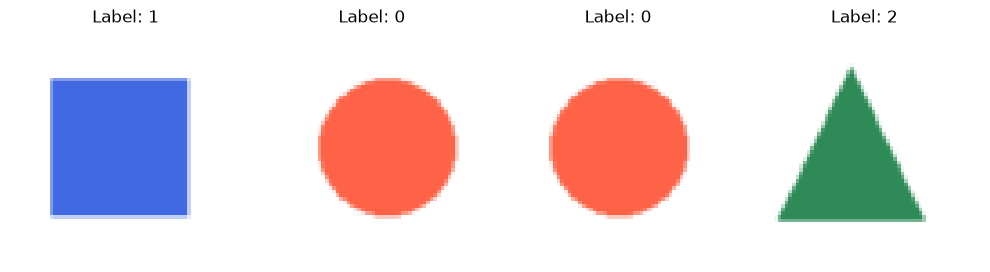

In [ ]:
import matplotlib.pyplot as plt


# 배치 하나 가져오기
images, labels = next(iter(train_loader))


# 시각화
plt.figure(figsize=(10, 3))

for i in range(len(labels)):

    plt.subplot(1, len(labels), i + 1)

    image = images[i].permute(1, 2, 0).numpy()   ##이거 왜 numpy로 바꿔주는지?

    plt.imshow(image)

    plt.title(f"Label: {labels[i].item()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader


# 1. CSV 불러오기
df = pd.read_csv(r"C:\image analysis\image_loader_practice\labels.csv")

print("원본 데이터:")
print(df)


# 2. 입력 데이터와 정답 분리
X = df.drop(columns=["label"])
y = df["label"]


# 3. 텐서 변환
X_tensor = torch.tensor(
    X.to_numpy(),
    dtype=torch.float32
)

y_tensor = torch.tensor(
    y.to_numpy(),
    dtype=torch.long
)


# 4. Dataset 생성
dataset = TensorDataset(
    X_tensor,
    y_tensor
)


# 5. DataLoader 생성
loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True
)


# 6. 배치 하나 가져오기
X_batch, y_batch = next(iter(loader))


# 7. 결과 확인
print("\n전체 데이터 수:", len(dataset))

print("입력 데이터:", X_batch.shape)
print("정답 데이터:", y_batch.shape)

print("\n입력 배치:")
print(X_batch)

print("\n정답 배치:")
print(y_batch)

원본 데이터:
           filename  label
0     circle_00.png      0
1     circle_01.png      0
2     circle_02.png      0
3     circle_03.png      0
4     circle_04.png      0
5     circle_05.png      0
6     circle_06.png      0
7     circle_07.png      0
8     circle_08.png      0
9     circle_09.png      0
10    square_00.png      1
11    square_01.png      1
12    square_02.png      1
13    square_03.png      1
14    square_04.png      1
15    square_05.png      1
16    square_06.png      1
17    square_07.png      1
18    square_08.png      1
19    square_09.png      1
20  triangle_00.png      2
21  triangle_01.png      2
22  triangle_02.png      2
23  triangle_03.png      2
24  triangle_04.png      2
25  triangle_05.png      2
26  triangle_06.png      2
27  triangle_07.png      2
28  triangle_08.png      2
29  triangle_09.png      2


TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.